In [2]:
import pandas as pd
import numpy as np


print("="*70)
print("ABLATION STUDY")
print("5-FOLD CROSS VALIDATION")
print("PART 1: DATASET PREPARATION")
print("="*70)



# =====================================================
# LOAD TON-IOT DATASET
# =====================================================

print("\nLoading TON-IoT Dataset")


dataset = pd.read_csv(
    "../data/train_test_network.csv"
)


print(
    "Dataset Shape:",
    dataset.shape
)



# =====================================================
# CLEAN DATASET
# SAME AS EXPERIMENT 3
# =====================================================

print("\nCleaning Dataset")


dataset.replace(
    "-",
    "unknown",
    inplace=True
)


dataset.fillna(
    "unknown",
    inplace=True
)


print(
    "Cleaning Completed"
)



# =====================================================
# DROP UNUSED FEATURES
# SAME AS EXPERIMENT 3
# =====================================================


drop_columns = [

    "src_ip",
    "dst_ip",

    "src_port",
    "dst_port",

    "ssl_subject",
    "ssl_issuer",

    "http_user_agent",

    "label"

]


dataset.drop(

    columns=drop_columns,

    inplace=True,

    errors="ignore"

)



print("\nDataset Shape After Feature Removal")


print(
    dataset.shape
)



# =====================================================
# CLASS DISTRIBUTION
# =====================================================


print("\nClass Distribution")


print(
    dataset["type"].value_counts()
)



print("\n")

print("="*70)
print("PART 1 COMPLETED")
print("="*70)

ABLATION STUDY
5-FOLD CROSS VALIDATION
PART 1: DATASET PREPARATION

Loading TON-IoT Dataset
Dataset Shape: (211043, 44)

Cleaning Dataset
Cleaning Completed

Dataset Shape After Feature Removal
(211043, 36)

Class Distribution
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64


PART 1 COMPLETED


In [3]:
import pandas as pd
import numpy as np


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    LabelEncoder
)

from sklearn.compose import ColumnTransformer



print("="*70)
print("ABLATION STUDY")
print("PART 2: DATA PREPROCESSING")
print("="*70)



# =====================================================
# SEPARATE FEATURES AND LABEL
# =====================================================


print("\nSeparating Features and Labels")


X = dataset.drop(
    "type",
    axis=1
)


y = dataset["type"]



print("\nFeature Shape")

print(
    "X:",
    X.shape
)


print(
    "y:",
    y.shape
)



# =====================================================
# LABEL ENCODING
# SAME AS EXPERIMENT 3
# =====================================================


print("\nEncoding Labels")


label_encoder = LabelEncoder()


y_encoded = label_encoder.fit_transform(

    y

)



print("\nClasses")


print(
    label_encoder.classes_
)



# =====================================================
# IDENTIFY FEATURE TYPES
# =====================================================


print("\nIdentifying Feature Types")


categorical_columns = X.select_dtypes(

    include="object"

).columns.tolist()



numerical_columns = X.select_dtypes(

    exclude="object"

).columns.tolist()



print(
    "Categorical Features:",
    len(categorical_columns)
)


print(
    "Numerical Features:",
    len(numerical_columns)
)



# =====================================================
# FIX DATA TYPES
# SAME AS EXPERIMENT 3
# =====================================================


print("\nFixing Data Types")



# categorical features

for col in categorical_columns:

    X[col] = X[col].astype(str)



# numerical features

for col in numerical_columns:

    X[col] = pd.to_numeric(

        X[col],

        errors="coerce"

    )



# replace invalid values

X[numerical_columns] = (

    X[numerical_columns]

    .fillna(0)

)



print(
    "Datatype Correction Completed"
)



# =====================================================
# DEFINE FEATURE GROUPS FOR ABLATION
# =====================================================


print("\nDefining Feature Groups")



# Traffic features

traffic_features = [

    "duration",

    "src_bytes",

    "dst_bytes",

    "missed_bytes",

    "src_pkts",

    "dst_pkts",

    "src_ip_bytes",

    "dst_ip_bytes"

]



# Protocol features

protocol_features = [

    "proto",

    "service",

    "conn_state"

]



# Application layer features

application_features = [

    "http_trans_depth",

    "http_method",

    "http_uri",

    "http_version",

    "http_request_body_len",

    "http_response_body_len",

    "http_status_code"

]



# DNS features

dns_features = [

    "dns_query",

    "dns_qclass",

    "dns_qtype",

    "dns_rcode",

    "dns_AA",

    "dns_RD",

    "dns_RA",

    "dns_rejected"

]



# SSL features

ssl_features = [

    "ssl_version",

    "ssl_cipher",

    "ssl_resumed",

    "ssl_established"

]



# Weird features

weird_features = [

    "weird_name",

    "weird_addl",

    "weird_notice"

]



print("Feature Groups Defined")



# =====================================================
# CREATE ABLATION FEATURE SETS
# =====================================================


ablation_sets = {


    "Baseline_All_Features":

        X.columns.tolist(),



    "Without_Traffic_Features":

        [

            col for col in X.columns

            if col not in traffic_features

        ],



    "Without_Protocol_Features":

        [

            col for col in X.columns

            if col not in protocol_features

        ],



    "Without_Application_Features":

        [

            col for col in X.columns

            if col not in application_features

        ],



    "Without_DNS_SSL_Features":

        [

            col for col in X.columns

            if col not in (

                dns_features +

                ssl_features

            )

        ]

}



print("\nAblation Experiments Created")



for name, features in ablation_sets.items():

    print(

        name,

        ":",

        len(features),

        "features"

    )



print("\n")

print("="*70)
print("PART 2 COMPLETED")
print("="*70)

ABLATION STUDY
PART 2: DATA PREPROCESSING

Separating Features and Labels

Feature Shape
X: (211043, 35)
y: (211043,)

Encoding Labels

Classes
['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

Identifying Feature Types
Categorical Features: 21
Numerical Features: 14

Fixing Data Types
Datatype Correction Completed

Defining Feature Groups
Feature Groups Defined

Ablation Experiments Created
Baseline_All_Features : 35 features
Without_Traffic_Features : 27 features
Without_Protocol_Features : 32 features
Without_Application_Features : 28 features
Without_DNS_SSL_Features : 23 features


PART 2 COMPLETED


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\2834404151.py:92: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X.select_dtypes(


In [4]:
import numpy as np


from sklearn.model_selection import StratifiedKFold


from sklearn.ensemble import RandomForestClassifier


from sklearn.compose import ColumnTransformer


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score

)



print("="*70)
print("ABLATION STUDY")
print("PART 3: RANDOM FOREST")
print("5-FOLD CROSS VALIDATION")
print("="*70)



# =====================================================
# STRATIFIED 5-FOLD
# SAME AS EXPERIMENT 3
# =====================================================


skf = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)



# =====================================================
# STORE RESULTS
# =====================================================


rf_ablation_results = []



# =====================================================
# LOOP THROUGH ABLATION EXPERIMENTS
# =====================================================


for experiment_name, selected_features in ablation_sets.items():


    print("\n")

    print("="*70)

    print(experiment_name)

    print("="*70)



    # -------------------------------------------------
    # SELECT FEATURES
    # -------------------------------------------------


    X_exp = X[selected_features].copy()



    # Store fold metrics

    accuracy_scores = []

    precision_scores = []

    recall_scores = []

    weighted_f1_scores = []

    macro_f1_scores = []



    # Store predictions for classification report

    all_y_true = []

    all_y_pred = []



    # =================================================
    # 5-FOLD CROSS VALIDATION
    # =================================================


    for fold, (train_index, valid_index) in enumerate(

        skf.split(

            X_exp,

            y_encoded

        ),

        start=1

    ):



        print("\nFold", fold)



        # -------------------------------------------------
        # SPLIT DATA
        # -------------------------------------------------


        X_train = X_exp.iloc[train_index].copy()

        X_valid = X_exp.iloc[valid_index].copy()



        y_train = y_encoded[train_index]

        y_valid = y_encoded[valid_index]



        # -------------------------------------------------
        # IDENTIFY FEATURE TYPES
        # -------------------------------------------------


        categorical_columns = X_train.select_dtypes(

            include="object"

        ).columns.tolist()



        numerical_columns = X_train.select_dtypes(

            exclude="object"

        ).columns.tolist()



        # -------------------------------------------------
        # PREPROCESSOR
        # SAME AS EXPERIMENT 3
        # -------------------------------------------------


        preprocessor = ColumnTransformer(

            transformers=[


                (

                    "cat",

                    OneHotEncoder(

                        handle_unknown="ignore",

                        sparse_output=False

                    ),

                    categorical_columns

                ),



                (

                    "num",

                    StandardScaler(),

                    numerical_columns

                )


            ]

        )



        # Fit only on training fold

        X_train_processed = preprocessor.fit_transform(

            X_train

        )


        X_valid_processed = preprocessor.transform(

            X_valid

        )



        print(

            "Processed Shape:",

            X_train_processed.shape

        )



        # =================================================
        # RANDOM FOREST MODEL
        # EXACT SAME AS EXPERIMENT 3
        # =================================================


        rf = RandomForestClassifier(

            n_estimators=200,

            random_state=42,

            n_jobs=-1

        )



        # Train

        rf.fit(

            X_train_processed,

            y_train

        )



        # Prediction

        predictions = rf.predict(

            X_valid_processed

        )



        # Store predictions

        all_y_true.extend(

            y_valid

        )


        all_y_pred.extend(

            predictions

        )



        # =================================================
        # METRICS
        # =================================================


        accuracy = accuracy_score(

            y_valid,

            predictions

        )


        precision = precision_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        recall = recall_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        weighted_f1 = f1_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        macro_f1 = f1_score(

            y_valid,

            predictions,

            average="macro",

            zero_division=0

        )



        accuracy_scores.append(

            accuracy

        )


        precision_scores.append(

            precision

        )


        recall_scores.append(

            recall

        )


        weighted_f1_scores.append(

            weighted_f1

        )


        macro_f1_scores.append(

            macro_f1

        )



        print(

            f"Accuracy     : {accuracy:.4f}"

        )

        print(

            f"Precision    : {precision:.4f}"

        )

        print(

            f"Recall       : {recall:.4f}"

        )

        print(

            f"Weighted F1  : {weighted_f1:.4f}"

        )

        print(

            f"Macro F1     : {macro_f1:.4f}"

        )



    # =================================================
    # FINAL RESULT FOR EACH ABLATION EXPERIMENT
    # =================================================


    print("\n")

    print("-"*70)

    print(

        experiment_name,

        "FINAL RESULT"

    )

    print("-"*70)



    print(

        f"Mean Accuracy    : {np.mean(accuracy_scores):.4f} ± {np.std(accuracy_scores):.4f}"

    )


    print(

        f"Mean Precision   : {np.mean(precision_scores):.4f} ± {np.std(precision_scores):.4f}"

    )


    print(

        f"Mean Recall      : {np.mean(recall_scores):.4f} ± {np.std(recall_scores):.4f}"

    )


    print(

        f"Mean Weighted F1 : {np.mean(weighted_f1_scores):.4f} ± {np.std(weighted_f1_scores):.4f}"

    )


    print(

        f"Mean Macro F1    : {np.mean(macro_f1_scores):.4f} ± {np.std(macro_f1_scores):.4f}"

    )



    # Save results

    rf_ablation_results.append(

        {


            "Experiment": experiment_name,


            "Features": len(selected_features),


            "Accuracy":

                np.mean(accuracy_scores),


            "Precision":

                np.mean(precision_scores),


            "Recall":

                np.mean(recall_scores),


            "Weighted_F1":

                np.mean(weighted_f1_scores),


            "Macro_F1":

                np.mean(macro_f1_scores)

        }

    )





print("\n")

print("="*70)

print("RANDOM FOREST ABLATION TRAINING COMPLETED")

print("="*70)

ABLATION STUDY
PART 3: RANDOM FOREST
5-FOLD CROSS VALIDATION


Baseline_All_Features

Fold 1


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\1869958305.py:164: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168834, 877)
Accuracy     : 0.9783
Precision    : 0.9787
Recall       : 0.9783
Weighted F1  : 0.9783
Macro F1     : 0.9577

Fold 2


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\1869958305.py:164: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168834, 881)
Accuracy     : 0.9793
Precision    : 0.9797
Recall       : 0.9793
Weighted F1  : 0.9794
Macro F1     : 0.9551

Fold 3


...

Processed Shape: (168834, 156)
Accuracy     : 0.9771
Precision    : 0.9776
Recall       : 0.9771
Weighted F1  : 0.9772
Macro F1     : 0.9549

Fold 4


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\1869958305.py:164: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168835, 156)
Accuracy     : 0.9770
Precision    : 0.9776
Recall       : 0.9770
Weighted F1  : 0.9771
Macro F1     : 0.9569

Fold 5


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\1869958305.py:164: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168835, 153)
Accuracy     : 0.9771
Precision    : 0.9778
Recall       : 0.9771
Weighted F1  : 0.9772
Macro F1     : 0.9552


----------------------------------------------------------------------
Without_DNS_SSL_Features FINAL RESULT
----------------------------------------------------------------------
Mean Accuracy    : 0.9775 ± 0.0005
Mean Precision   : 0.9779 ± 0.0004
Mean Recall      : 0.9775 ± 0.0005
Mean Weighted F1 : 0.9775 ± 0.0005
Mean Macro F1    : 0.9561 ± 0.0011


RANDOM FOREST ABLATION TRAINING COMPLETED


RANDOM FOREST ABLATION RESULTS


Random Forest Ablation Performance
                     Experiment  Features  Accuracy  Precision    Recall  \
0  Without_Application_Features        28  0.978090   0.978570  0.978090   
1         Baseline_All_Features        35  0.978038   0.978529  0.978038   
2      Without_DNS_SSL_Features        23  0.977450   0.977945  0.977450   
3     Without_Protocol_Features        32  0.968992   0.969506  0.968992   
4      Without_Traffic_Features        27  0.670247   0.785468  0.670247   

   Weighted_F1  Macro_F1  
0     0.978165  0.956521  
1     0.978117  0.956243  
2     0.977531  0.956119  
3     0.969180  0.946451  
4     0.631263  0.609285  


PERFORMANCE DROP FROM BASELINE
                     Experiment  Features  Accuracy  Accuracy_Drop  \
0  Without_Application_Features        28  0.978090      -0.000052   
1         Baseline_All_Features        35  0.978038       0.000000   
2      Without_DNS_SSL_Features        23  0.977450       0.000588   


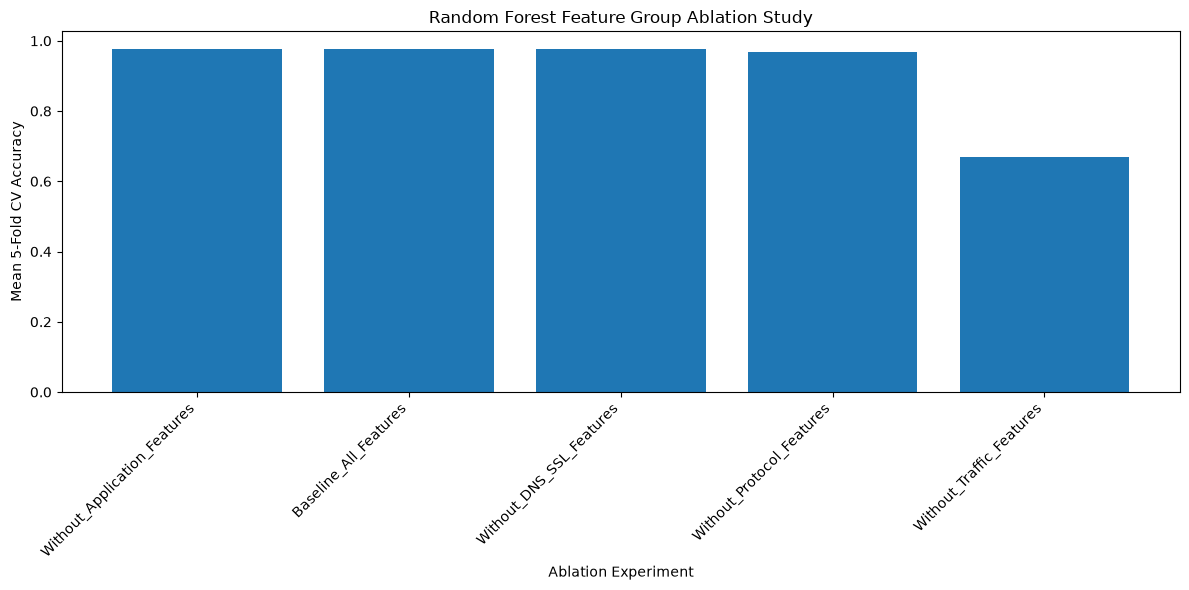



RANDOM FOREST ABLATION ANALYSIS COMPLETED


In [5]:
import pandas as pd
import matplotlib.pyplot as plt



print("="*70)
print("RANDOM FOREST ABLATION RESULTS")
print("="*70)



# =====================================================
# CREATE RESULTS DATAFRAME
# =====================================================


rf_ablation_results_df = pd.DataFrame(

    rf_ablation_results

)



# =====================================================
# SORT RESULTS BY ACCURACY
# =====================================================


rf_ablation_results_df = (

    rf_ablation_results_df

    .sort_values(

        by="Accuracy",

        ascending=False

    )

    .reset_index(drop=True)

)



print("\n")

print("Random Forest Ablation Performance")

print("="*70)


print(

    rf_ablation_results_df

)



# =====================================================
# CALCULATE PERFORMANCE DROP
# FROM BASELINE
# =====================================================


baseline_accuracy = (

    rf_ablation_results_df

    .loc[

        rf_ablation_results_df["Experiment"]

        ==

        "Baseline_All_Features",

        "Accuracy"

    ]

    .values[0]

)



rf_ablation_results_df["Accuracy_Drop"] = (

    baseline_accuracy

    -

    rf_ablation_results_df["Accuracy"]

)



print("\n")

print("="*70)

print("PERFORMANCE DROP FROM BASELINE")

print("="*70)



print(

    rf_ablation_results_df[

        [

            "Experiment",

            "Features",

            "Accuracy",

            "Accuracy_Drop",

            "Weighted_F1",

            "Macro_F1"

        ]

    ]

)



# =====================================================
# FEATURE CONTRIBUTION RANKING
# =====================================================


print("\n")

print("="*70)

print("FEATURE GROUP CONTRIBUTION")

print("="*70)



feature_impact = (

    rf_ablation_results_df

    [

        [

            "Experiment",

            "Accuracy_Drop"

        ]

    ]

    .sort_values(

        by="Accuracy_Drop",

        ascending=False

    )

)



print(feature_impact)



print("\nInterpretation:")

print(

    "Higher Accuracy Drop = More Important Feature Group"

)



# =====================================================
# VISUALIZATION
# =====================================================


plt.figure(

    figsize=(12,6)

)



plt.bar(

    rf_ablation_results_df["Experiment"],

    rf_ablation_results_df["Accuracy"]

)



plt.xticks(

    rotation=45,

    ha="right"

)



plt.ylabel(

    "Mean 5-Fold CV Accuracy"

)



plt.xlabel(

    "Ablation Experiment"

)



plt.title(

    "Random Forest Feature Group Ablation Study"

)



plt.tight_layout()



plt.show()



# =====================================================
# COMPLETION
# =====================================================


print("\n")

print("="*70)

print("RANDOM FOREST ABLATION ANALYSIS COMPLETED")

print("="*70)

In [6]:
import numpy as np


from sklearn.model_selection import StratifiedKFold


from xgboost import XGBClassifier


from sklearn.compose import ColumnTransformer


from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score

)



print("="*70)
print("ABLATION STUDY")
print("PART 5: XGBOOST")
print("5-FOLD CROSS VALIDATION")
print("="*70)



# =====================================================
# STRATIFIED 5-FOLD
# SAME AS EXPERIMENT 3
# =====================================================


skf = StratifiedKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)



# =====================================================
# STORE RESULTS
# =====================================================


xgb_ablation_results = []



# =====================================================
# LOOP THROUGH ABLATION EXPERIMENTS
# =====================================================


for experiment_name, selected_features in ablation_sets.items():


    print("\n")

    print("="*70)

    print(experiment_name)

    print("="*70)



    # -------------------------------------------------
    # SELECT FEATURES
    # -------------------------------------------------


    X_exp = X[selected_features].copy()



    # Store fold metrics

    accuracy_scores = []

    precision_scores = []

    recall_scores = []

    weighted_f1_scores = []

    macro_f1_scores = []



    # =================================================
    # 5-FOLD CROSS VALIDATION
    # =================================================


    for fold, (train_index, valid_index) in enumerate(

        skf.split(

            X_exp,

            y_encoded

        ),

        start=1

    ):



        print("\nFold", fold)



        # -------------------------------------------------
        # SPLIT DATA
        # -------------------------------------------------


        X_train = X_exp.iloc[train_index].copy()

        X_valid = X_exp.iloc[valid_index].copy()



        y_train = y_encoded[train_index]

        y_valid = y_encoded[valid_index]



        # -------------------------------------------------
        # IDENTIFY FEATURE TYPES
        # -------------------------------------------------


        categorical_columns = X_train.select_dtypes(

            include="object"

        ).columns.tolist()



        numerical_columns = X_train.select_dtypes(

            exclude="object"

        ).columns.tolist()



        # -------------------------------------------------
        # PREPROCESSOR
        # SAME AS EXPERIMENT 3
        # -------------------------------------------------


        preprocessor = ColumnTransformer(

            transformers=[


                (

                    "cat",

                    OneHotEncoder(

                        handle_unknown="ignore",

                        sparse_output=False

                    ),

                    categorical_columns

                ),



                (

                    "num",

                    StandardScaler(),

                    numerical_columns

                )


            ]

        )



        # Fit only training fold

        X_train_processed = preprocessor.fit_transform(

            X_train

        )


        X_valid_processed = preprocessor.transform(

            X_valid

        )



        print(

            "Processed Shape:",

            X_train_processed.shape

        )



        # =================================================
        # XGBOOST MODEL
        # EXACT SAME AS EXPERIMENT 3
        # =================================================


        xgb = XGBClassifier(

            n_estimators=200,

            learning_rate=0.1,

            random_state=42,

            n_jobs=-1,

            objective="multi:softprob",

            eval_metric="mlogloss"

        )



        # Train model

        xgb.fit(

            X_train_processed,

            y_train

        )



        # Prediction

        predictions = xgb.predict(

            X_valid_processed

        )



        # =================================================
        # METRICS
        # =================================================


        accuracy = accuracy_score(

            y_valid,

            predictions

        )


        precision = precision_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        recall = recall_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        weighted_f1 = f1_score(

            y_valid,

            predictions,

            average="weighted",

            zero_division=0

        )


        macro_f1 = f1_score(

            y_valid,

            predictions,

            average="macro",

            zero_division=0

        )



        # Store fold results

        accuracy_scores.append(

            accuracy

        )


        precision_scores.append(

            precision

        )


        recall_scores.append(

            recall

        )


        weighted_f1_scores.append(

            weighted_f1

        )


        macro_f1_scores.append(

            macro_f1

        )



        print(

            f"Accuracy     : {accuracy:.4f}"

        )

        print(

            f"Precision    : {precision:.4f}"

        )

        print(

            f"Recall       : {recall:.4f}"

        )

        print(

            f"Weighted F1  : {weighted_f1:.4f}"

        )

        print(

            f"Macro F1     : {macro_f1:.4f}"

        )



    # =================================================
    # FINAL RESULT FOR EACH EXPERIMENT
    # =================================================


    print("\n")

    print("-"*70)

    print(

        experiment_name,

        "FINAL RESULT"

    )

    print("-"*70)



    print(

        f"Mean Accuracy    : {np.mean(accuracy_scores):.4f} ± {np.std(accuracy_scores):.4f}"

    )


    print(

        f"Mean Precision   : {np.mean(precision_scores):.4f} ± {np.std(precision_scores):.4f}"

    )


    print(

        f"Mean Recall      : {np.mean(recall_scores):.4f} ± {np.std(recall_scores):.4f}"

    )


    print(

        f"Mean Weighted F1 : {np.mean(weighted_f1_scores):.4f} ± {np.std(weighted_f1_scores):.4f}"

    )


    print(

        f"Mean Macro F1    : {np.mean(macro_f1_scores):.4f} ± {np.std(macro_f1_scores):.4f}"

    )



    # =================================================
    # SAVE RESULTS
    # =================================================


    xgb_ablation_results.append(

        {


            "Experiment": experiment_name,


            "Features": len(selected_features),


            "Accuracy":

                np.mean(accuracy_scores),


            "Precision":

                np.mean(precision_scores),


            "Recall":

                np.mean(recall_scores),


            "Weighted_F1":

                np.mean(weighted_f1_scores),


            "Macro_F1":

                np.mean(macro_f1_scores)


        }

    )





print("\n")

print("="*70)

print("XGBOOST ABLATION TRAINING COMPLETED")

print("="*70)

ABLATION STUDY
PART 5: XGBOOST
5-FOLD CROSS VALIDATION


Baseline_All_Features

Fold 1


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\3284819110.py:156: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168834, 877)
Accuracy     : 0.9787
Precision    : 0.9795
Recall       : 0.9787
Weighted F1  : 0.9789
Macro F1     : 0.9565

Fold 2


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\3284819110.py:156: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168834, 881)
Accuracy     : 0.9800
Precision    : 0.9807
Recall       : 0.9800
Weighted F1  : 0.9802
Macro F1     : 0.9546

Fold 3


...

Processed Shape: (168834, 156)
Accuracy     : 0.9774
Precision    : 0.9779
Recall       : 0.9774
Weighted F1  : 0.9775
Macro F1     : 0.9552

Fold 4


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\3284819110.py:156: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168835, 156)
Accuracy     : 0.9776
Precision    : 0.9784
Recall       : 0.9776
Weighted F1  : 0.9778
Macro F1     : 0.9556

Fold 5


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_21044\3284819110.py:156: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


Processed Shape: (168835, 153)
Accuracy     : 0.9774
Precision    : 0.9781
Recall       : 0.9774
Weighted F1  : 0.9776
Macro F1     : 0.9535


----------------------------------------------------------------------
Without_DNS_SSL_Features FINAL RESULT
----------------------------------------------------------------------
Mean Accuracy    : 0.9777 ± 0.0005
Mean Precision   : 0.9783 ± 0.0005
Mean Recall      : 0.9777 ± 0.0005
Mean Weighted F1 : 0.9778 ± 0.0005
Mean Macro F1    : 0.9546 ± 0.0009


XGBOOST ABLATION TRAINING COMPLETED


XGBOOST ABLATION RESULTS


XGBoost Ablation Performance
                     Experiment  Features  Accuracy  Precision    Recall  \
0  Without_Application_Features        28  0.978729   0.979488  0.978729   
1         Baseline_All_Features        35  0.978715   0.979481  0.978715   
2      Without_DNS_SSL_Features        23  0.977696   0.978341  0.977696   
3     Without_Protocol_Features        32  0.969224   0.970106  0.969224   
4      Without_Traffic_Features        27  0.669413   0.784324  0.669413   

   Weighted_F1  Macro_F1  
0     0.978917  0.955310  
1     0.978907  0.955069  
2     0.977835  0.954645  
3     0.969547  0.944901  
4     0.630123  0.604291  


XGBOOST PERFORMANCE DROP FROM BASELINE
                     Experiment  Features  Accuracy  Accuracy_Drop  \
0  Without_Application_Features        28  0.978729      -0.000014   
1         Baseline_All_Features        35  0.978715       0.000000   
2      Without_DNS_SSL_Features        23  0.977696       0.001019   
3   

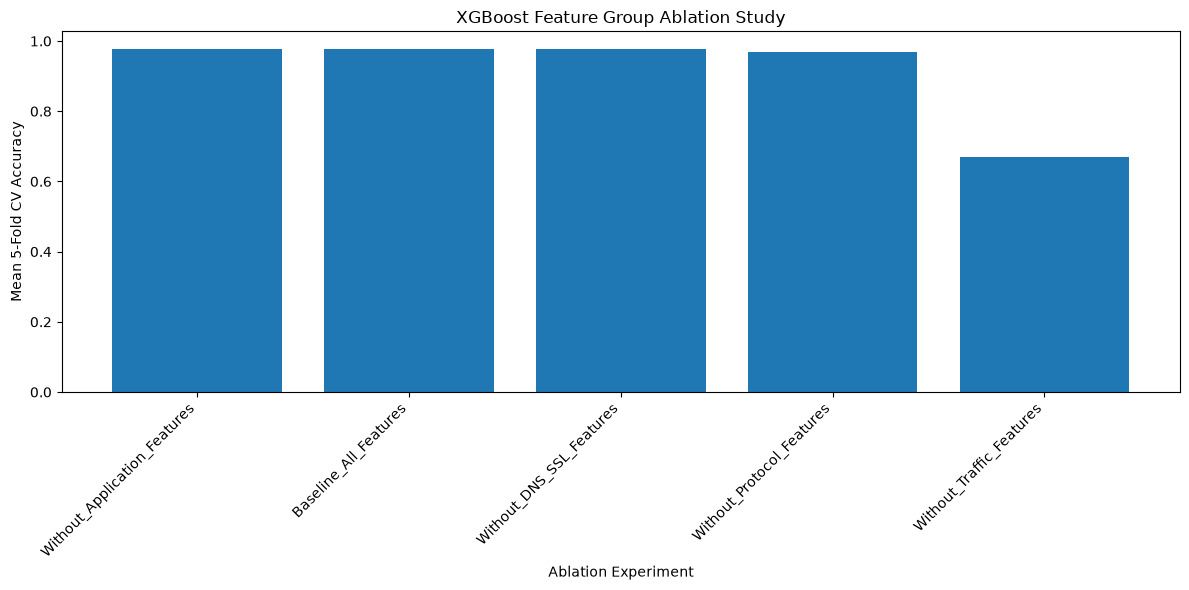



XGBOOST ABLATION ANALYSIS COMPLETED


In [7]:
import pandas as pd
import matplotlib.pyplot as plt



print("="*70)
print("XGBOOST ABLATION RESULTS")
print("="*70)



# =====================================================
# CREATE RESULTS DATAFRAME
# =====================================================


xgb_ablation_results_df = pd.DataFrame(

    xgb_ablation_results

)



# =====================================================
# SORT RESULTS BY ACCURACY
# =====================================================


xgb_ablation_results_df = (

    xgb_ablation_results_df

    .sort_values(

        by="Accuracy",

        ascending=False

    )

    .reset_index(drop=True)

)



print("\n")

print("XGBoost Ablation Performance")

print("="*70)


print(

    xgb_ablation_results_df

)



# =====================================================
# CALCULATE PERFORMANCE DROP
# FROM BASELINE
# =====================================================


baseline_accuracy = (

    xgb_ablation_results_df

    .loc[

        xgb_ablation_results_df["Experiment"]

        ==

        "Baseline_All_Features",

        "Accuracy"

    ]

    .values[0]

)



xgb_ablation_results_df["Accuracy_Drop"] = (

    baseline_accuracy

    -

    xgb_ablation_results_df["Accuracy"]

)



print("\n")

print("="*70)

print("XGBOOST PERFORMANCE DROP FROM BASELINE")

print("="*70)



print(

    xgb_ablation_results_df[

        [

            "Experiment",

            "Features",

            "Accuracy",

            "Accuracy_Drop",

            "Weighted_F1",

            "Macro_F1"

        ]

    ]

)



# =====================================================
# FEATURE GROUP CONTRIBUTION RANKING
# =====================================================


print("\n")

print("="*70)

print("FEATURE GROUP CONTRIBUTION")

print("="*70)



feature_impact = (

    xgb_ablation_results_df

    [

        [

            "Experiment",

            "Accuracy_Drop"

        ]

    ]

    .sort_values(

        by="Accuracy_Drop",

        ascending=False

    )

)



print(feature_impact)



print("\nInterpretation:")

print(

    "Higher accuracy drop indicates greater contribution of that feature group."

)



# =====================================================
# VISUALIZATION
# =====================================================


plt.figure(

    figsize=(12,6)

)



plt.bar(

    xgb_ablation_results_df["Experiment"],

    xgb_ablation_results_df["Accuracy"]

)



plt.xticks(

    rotation=45,

    ha="right"

)



plt.ylabel(

    "Mean 5-Fold CV Accuracy"

)



plt.xlabel(

    "Ablation Experiment"

)



plt.title(

    "XGBoost Feature Group Ablation Study"

)



plt.tight_layout()



plt.show()



# =====================================================
# COMPLETION
# =====================================================


print("\n")

print("="*70)

print("XGBOOST ABLATION ANALYSIS COMPLETED")

print("="*70)